# Snowshoe hares at Bonanza Creek Experimental Forest
## Week 4 - Linear Regression



In [8]:
import pandas as pd
import os # os package
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

fp = os.path.join('data', '55_Hare_Data_2012.txt')
# obs = pd.read_csv(os.path.join('data', 'knb-lter-bnz', '55_Hare_Data_2012.txt'))
bunny = pd.read_csv(fp)

In [6]:
bunny.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [9]:
bunny.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [16]:
bunny['date'] = pd.to_datetime(bunny['date'])
print(bunny['date'].dtype)

datetime64[ns]


In [17]:
bunny['date'].dtype

dtype('<M8[ns]')

## Examine the hare's age data

In [21]:
bunny['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When you make a decision, document it.
We will keep all hares with a j as juvenile, all hares with an a as an adult.

In [28]:
# Update age calues to juvenile and adult for observations where 'a' and 'j' are included
bunny.loc[bunny['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
bunny.loc[bunny['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

# Filter for confirmed observations of juvenile and  adults hares
obs_juv_adult = bunny[bunny['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hare observations (caputures):', len(obs_juv_adult))

Number of juvenile and adult hare observations (caputures): 1155


In [ ]:
# Extracted the year
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year


In [30]:
obs_juv_adult.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study,data,year
108,1999-06-23,NaN,bonrip,2C,68,69,M,juvenile,395.0,126.0,NaN,643.0,53,Population,1999-06-23,1999
109,1999-06-23,NaN,bonrip,2E,70,71,F,juvenile,420.0,137.0,NaN,653.0,53,Population,1999-06-23,1999
110,1999-06-23,NaN,bonrip,3D,72,73,M,juvenile,445.0,144.0,NaN,944.0,53,Population,1999-06-23,1999
111,1999-06-23,NaN,bonrip,4B,76,77,M,juvenile,410.0,115.0,NaN,663.0,53,Population,1999-06-23,1999
112,1999-06-23,NaN,bonrip,4C,78,79,M,juvenile,430.0,132.0,NaN,670.0,53,Population,1999-06-23,1999


In [34]:
# count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [35]:
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

<Axes: title={'center': 'Juvenile and snowshoe hare captures'}, xlabel='Year', ylabel='Number of captures'>

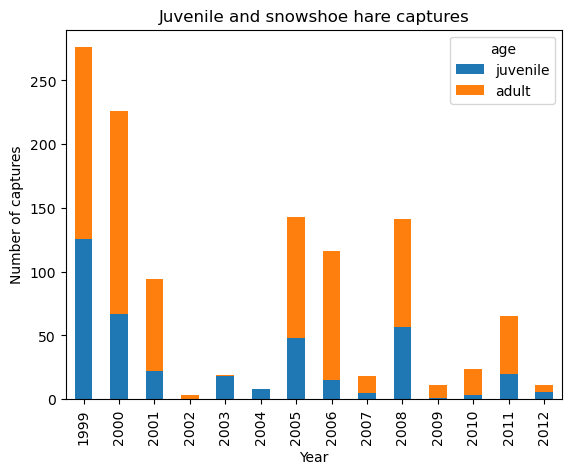

In [38]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar',
                                         stacked=True,
                                         title='Juvenile and snowshoe hare captures',
                                         xlabel='Year',
                                         ylabel='Number of captures')

how many traps, how many visits, more info needed to understand why the data is less in some years.

### Plotting with matplotlib

<function matplotlib.pyplot.show(close=None, block=None)>

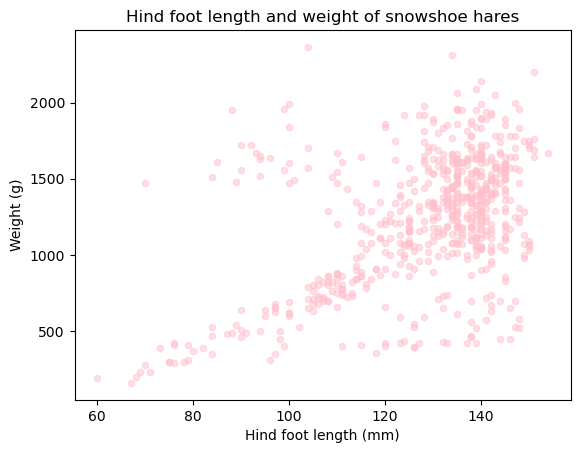

In [46]:
# Initialize empty figure (fig) and axes (ax)
fig, ax = plt.subplots()

# Add scatter plot of hares data to our figure's axes
obs_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax, alpha=0.5, color='pink')

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')
# Display
plt.show

## Linear REgression
For our analysis we want to investigate possible relations between hind foot length and weight for juvenile hares.

In [ ]:
juv_w_hft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

Number of juvenile hare captures with hind foot and weight measurements: 265


<Axes: xlabel='hindft', ylabel='weight'>

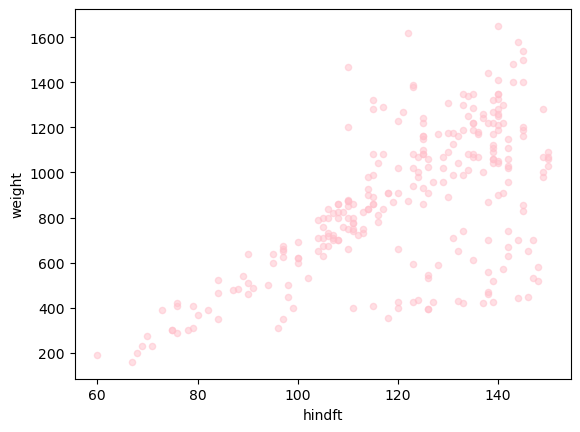

In [61]:
# Subset juvenile hares and drop rows missing hind foot or weight measurements
juv_w_hft= obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

print("Number of juvenile hare captures with hind foot and weight measurements:", len(juv_w_hft))
juv_w_hft.plot.scatter(x='hindft', y='weight', alpha=0.5, color='pink')

In [53]:
model = smf.ols('weight ~ hindft', data=juv_w_hft).fit()

In [54]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [59]:
intercept = model.params['Intercept']
print('y-intercept:', intercept)

slope = model.params['hindft']
print("Slope:", slope)

y-intercept: -352.77198564640645
Slope: 10.092239638623006


In [62]:
print('R^2', model.rsquared)

R^2 0.3871164783665738


R^2 is the coefficient of the determination. It is between 0 and 1. R^2=1 is a perfect fit of the model to the data. We interpret it as the propertion of variance in the response that is explained by the least squares line with the predictor 

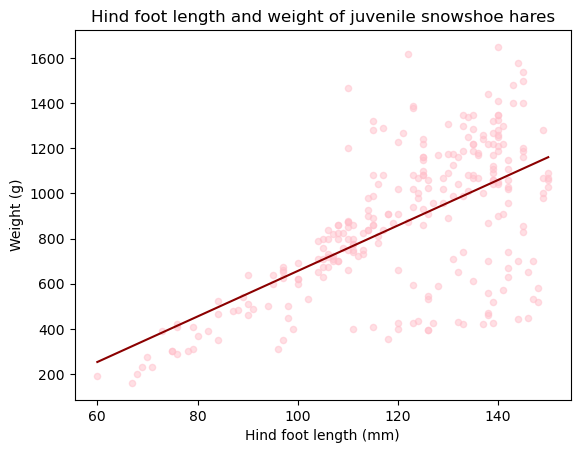

In [66]:
# Smallest and largest hind foot lengths
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add data to axes
juv_w_hft.plot(kind='scatter', 
                             x='hindft', 
                             y='weight', 
                             alpha=0.5,     # Adjust transparency
                             ax=ax,
                             color='pink')         # Add plot to axes

# Add regression line to axes
ax.plot([x_start, x_end], 
        [intercept + slope*x_start, intercept + slope*x_end],
        color='darkred')

# Update axes
ax.set_title('Hind foot length and weight of juvenile snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display figure
plt.show()

In [68]:
model.resid

108    -523.850209
109    -609.864845
110    -655.510522
111    -397.835573
112    -549.403647
           ...    
3355    -46.820937
3359    117.625625
3360    117.625625
3367   -276.175259
3369    -37.189895
Length: 265, dtype: float64